### Option B — recursive net, scheduled sampling

Trabajo Futuro. Sensors + **own last velocity and quaternion** (no NED position). Not the defended method (A8q).

B1: same 1 s windows / 0.1 s extract / residual δv + 0.1 s Δθ as A8. Recur through **v̂ + q̂**. Position integrate is A8-style (`pos += v̂·1.0` on 1 s hops). K=40 unroll; `p_gt` 1→0 over the first 40% of epochs, then stay at 0.

Data: `option_a/dataset.csv`. **Restart + Run All.** First print must be `RUN_ID=B1_SS`.


In [1]:
import os, random, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 1
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

IMU_FS = 160
WIN_SEC, EXTRACT_SEC, HOP_SEC, RTE_SEC = 1.0, 0.1, 1.0, 1.0
W = int(WIN_SEC * IMU_FS)
STRIDE = int(EXTRACT_SEC * IMU_FS)
HOP_N = int(round(HOP_SEC / EXTRACT_SEC))
K_UNROLL = 40
SS_ANNEAL = 0.4
BATCH_SIZE, EPOCHS, LR = 16, 10, 1e-3
LAMBDA_ROT, LAMBDA_POS = 1.0, 0.25
VAL_FRAC, TEST_FRAC, GAP = 0.15, 0.15, HOP_N
_cands = [os.path.join("..", "option_a"), os.path.join("option_a")]
DATA = next((p for p in _cands if os.path.exists(os.path.join(p, "dataset.csv"))), None)
assert DATA, "run option_a/make_dataset.m first"
print("RUN_ID=B1_SS", device, "K", K_UNROLL, "hop", HOP_SEC, "anneal", SS_ANNEAL, "data", DATA)


RUN_ID=B1_SS cuda K 40 hop 1.0 anneal 0.4 data ..\option_a


In [2]:
COLS = [
    "accx","accy","accz","wx","wy","wz",
    "magx","magy","magz","velx","vely","velz",
    "posx","posy","posz","qw","qx","qy","qz",
]
df = pd.read_csv(os.path.join(DATA, "dataset.csv"), names=COLS)
meas = df[COLS[:12]].to_numpy(np.float32)
pos = df[["posx","posy","posz"]].to_numpy(np.float32)
quat = df[["qw","qx","qy","qz"]].to_numpy(np.float32)
print(df.shape)


(22560, 19)


In [3]:
def q_normalize(q, eps=1e-8):
    return q / (np.linalg.norm(q, axis=-1, keepdims=True) + eps)

def q_conj(q):
    o = q.copy(); o[..., 1:] *= -1; return o

def q_mul(a, b):
    aw, ax, ay, az = (a[..., k] for k in range(4))
    bw, bx, by, bz = (b[..., k] for k in range(4))
    return np.stack([
        aw*bw - ax*bx - ay*by - az*bz,
        aw*bx + ax*bw + ay*bz - az*by,
        aw*by - ax*bz + ay*bw + az*bx,
        aw*bz + ax*by - ay*bx + az*bw,
    ], axis=-1)

def q_delta(q0, q1):
    return q_normalize(q_mul(q_conj(q_normalize(q0)), q_normalize(q1)))

def quat_to_rotvec(q):
    q = q_normalize(q)
    q = np.where(q[..., :1] < 0, -q, q)
    w = np.clip(q[..., 0], -1, 1)
    xyz = q[..., 1:]
    n = np.linalg.norm(xyz, axis=-1, keepdims=True)
    angle = 2 * np.arccos(w)
    axis = xyz / np.clip(n, 1e-8, None)
    return (axis * angle[..., None]).astype(np.float32)

def rotvec_to_quat(v, eps=1e-8):
    angle = np.linalg.norm(v, axis=-1, keepdims=True)
    axis = v / np.clip(angle, eps, None)
    half = 0.5 * angle
    return np.concatenate([np.cos(half), axis * np.sin(half)], -1).astype(np.float32)

def q_ang_deg(qa, qb):
    d = np.clip(np.abs((q_normalize(qa) * q_normalize(qb)).sum(-1)), -1, 1)
    return np.degrees(2 * np.arccos(d))

def q_norm_t(q, eps=1e-8):
    return q / q.norm(dim=-1, keepdim=True).clamp(min=eps)

def q_mul_t(a, b):
    aw, ax, ay, az = a.unbind(-1)
    bw, bx, by, bz = b.unbind(-1)
    return torch.stack([
        aw*bw - ax*bx - ay*by - az*bz,
        aw*bx + ax*bw + ay*bz - az*by,
        aw*by - ax*bz + ay*bw + az*bx,
        aw*bz + ax*by - ay*bx + az*bw,
    ], -1)

def rotvec_to_quat_t(v, eps=1e-8):
    angle = v.norm(dim=-1, keepdim=True)
    axis = v / angle.clamp(min=eps)
    half = 0.5 * angle
    return torch.cat([torch.cos(half), axis * torch.sin(half)], -1)


In [4]:
quat = q_normalize(quat)
ends = np.arange(W - 1, len(df), STRIDE)
X = np.stack([meas[t - W + 1:t + 1].T for t in ends], 0)
v_gps = meas[ends, 9:12]
vel = (pos[ends] - pos[ends - (W - 1)]) / WIN_SEC
dv = vel - v_gps
drot = quat_to_rotvec(q_delta(quat[np.maximum(ends - STRIDE, 0)], quat[ends]))
Y = np.concatenate([dv, drot], 1)
pos_end, q_end = pos[ends], quat[ends]
print(X.shape, Y.shape, "dv std", dv.std(0))


(1401, 12, 160) (1401, 6) dv std [0.34355506 0.33659002 0.26131845]


In [5]:
N = len(X)
n_test, n_val = int(N * TEST_FRAC), int(N * VAL_FRAC)
n_train = N - n_val - n_test - 2 * GAP
tr = slice(0, n_train)
va = slice(n_train + GAP, n_train + GAP + n_val)
te = slice(n_train + GAP + n_val + GAP, N)
X_tr, Y_tr = X[tr], Y[tr]
X_va, Y_va = X[va], Y[va]
X_te, Y_te = X[te], Y[te]
pos_tr, q_tr = pos_end[tr], q_end[tr]
pos_va, q_va = pos_end[va], q_end[va]
pos_te, q_te = pos_end[te], q_end[te]
v_gps_tr, v_gps_va, v_gps_te = v_gps[tr], v_gps[va], v_gps[te]
vel_tr, vel_va, vel_te = vel[tr], vel[va], vel[te]
t_end = ends / IMU_FS
print(len(X_tr), len(X_va), len(X_te), "1s hops", (len(X_te) + HOP_N - 1) // HOP_N)
print(f"TRAIN {t_end[tr][0]:.1f}–{t_end[tr][-1]:.1f}s  VAL {t_end[va][0]:.1f}–{t_end[va][-1]:.1f}s  TEST {t_end[te][0]:.1f}–{t_end[te][-1]:.1f}s")


961 210 210 1s hops 21
TRAIN 1.0–97.0s  VAL 98.1–119.0s  TEST 120.1–141.0s


In [6]:
feat_mean, feat_std = X_tr.mean((0, 2)), X_tr.std((0, 2)) + 1e-8
y_mean, y_std = Y_tr.mean(0), Y_tr.std(0) + 1e-8
y_mean_t = torch.tensor(y_mean)
y_std_t = torch.tensor(y_std)
vel_m, vel_s = vel_tr.mean(0), vel_tr.std(0) + 1e-8
vel_m_t = torch.tensor(vel_m)
vel_s_t = torch.tensor(vel_s)

def nX(a):
    return (a - feat_mean[None, :, None]) / feat_std[None, :, None]

def nY(a):
    return (a - y_mean) / y_std

def denorm_t(p):
    return p * y_std_t.to(p.device) + y_mean_t.to(p.device)

X_tr_n, X_va_n, X_te_n = nX(X_tr), nX(X_va), nX(X_te)
Y_tr_n = nY(Y_tr)


In [7]:
class SeqDS(Dataset):
    def __init__(self, x, y, vg, vel, pos, quat, k):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
        self.vg = torch.tensor(vg, dtype=torch.float32)
        self.vel = torch.tensor(vel, dtype=torch.float32)
        self.pos = torch.tensor(pos, dtype=torch.float32)
        self.quat = torch.tensor(quat, dtype=torch.float32)
        self.k = k
        self.n = len(x) - k
    def __len__(self):
        return max(self.n, 0)
    def __getitem__(self, i):
        sl = slice(i, i + self.k + 1)
        return (self.x[sl], self.y[sl], self.vg[sl], self.vel[sl], self.pos[sl], self.quat[sl])

train_loader = DataLoader(SeqDS(X_tr_n, Y_tr_n, v_gps_tr, vel_tr, pos_tr, q_tr, K_UNROLL), BATCH_SIZE, shuffle=True)
print("train seq", len(train_loader.dataset), "windows", len(X_tr))


train seq 921 windows 961


In [8]:
class TcnBlock(nn.Module):
    def __init__(self, ch, k, d):
        super().__init__()
        pad = (k - 1) * d // 2
        self.f = nn.Sequential(
            nn.Conv1d(ch, ch, k, padding=pad, dilation=d),
            nn.ReLU(),
            nn.Conv1d(ch, ch, k, padding=pad, dilation=d),
        )
        self.act = nn.ReLU()
    def forward(self, x):
        return self.act(x + self.f(x))

class RecModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Conv1d(12, 64, 5, padding=2)
        self.tcn = nn.Sequential(
            TcnBlock(64, 5, 1), TcnBlock(64, 5, 2),
            TcnBlock(64, 5, 4), TcnBlock(64, 5, 8),
        )
        self.prev = nn.Sequential(nn.Linear(7, 32), nn.ReLU())
        self.head_v = nn.Sequential(nn.Linear(160, 64), nn.ReLU(), nn.Linear(64, 3))
        self.head_q = nn.Sequential(nn.Linear(160, 64), nn.ReLU(), nn.Linear(64, 3))
    def forward(self, x, prev_vq):
        z = torch.relu(self.stem(x))
        z = self.tcn(z)
        h = torch.cat([z.mean(-1), z[:, :, -1], self.prev(prev_vq)], 1)
        return torch.cat([self.head_v(h), self.head_q(h)], 1)

_m = RecModel()
print(_m(torch.zeros(2, 12, W), torch.zeros(2, 7)).shape, "params", sum(p.numel() for p in _m.parameters()), "prev=vel+quat")


torch.Size([2, 6]) params 189510 prev=vel+quat


  0  p_gt 1.00  train 57.361  val ATE 1.663 m  quat 10.64
  5  p_gt 0.00  train 3.359  val ATE 1.406 m  quat 4.06
  9  p_gt 0.00  train 1.217  val ATE 1.658 m  quat 6.43


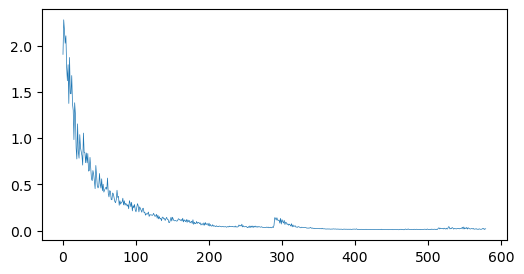

best val metric 1.369552771250407


In [9]:
def ate_rte(est, ref, hop=HOP_SEC, sec=RTE_SEC):
    ate = float(np.sqrt(((est - ref) ** 2).sum(1).mean()))
    w = max(int(round(sec / hop)), 1)
    rel = [
        np.linalg.norm((est[i + w] - est[i]) - (ref[i + w] - ref[i]))
        for i in range(0, len(est) - w, max(w // 2, 1))
    ]
    return ate, float(np.mean(rel)) if rel else float("nan")

def integrate_pos(vel_1s, pos0):
    n = len(vel_1s)
    out = np.zeros((n, 3), np.float32)
    out[0] = pos0
    for t in range(1, n):
        out[t] = out[t - 1] + vel_1s[t] * HOP_SEC
    return out

def p_gt_of(epoch):
    return max(0.0, 1.0 - epoch / max(EPOCHS * SS_ANNEAL, 1))

def pack_prev(v, q):
    return torch.cat([(v - vel_m_t.to(v.device)) / vel_s_t.to(v.device), q_norm_t(q)], -1)

@torch.no_grad()
def closed_loop(Xn, vg, vel_ref, pos_ref, q_ref, use_gt=False):
    model.eval()
    v = torch.tensor(vel_ref[0], device=device).unsqueeze(0)
    q = torch.tensor(q_ref[0], device=device).unsqueeze(0)
    v_h = [vel_ref[0].copy()]
    q_h = [q_ref[0].copy()]
    for i in range(1, len(Xn)):
        prev_v = torch.tensor(vel_ref[i - 1], device=device).unsqueeze(0) if use_gt else v
        prev_q = torch.tensor(q_ref[i - 1], device=device).unsqueeze(0) if use_gt else q
        xb = torch.tensor(Xn[i:i + 1], device=device)
        inc = denorm_t(model(xb, pack_prev(prev_v, prev_q)))
        v = torch.tensor(vg[i], device=device).unsqueeze(0) + inc[:, :3]
        q = q_norm_t(q_mul_t(prev_q, rotvec_to_quat_t(inc[:, 3:])))
        v_h.append(v.squeeze(0).cpu().numpy())
        q_h.append(q.squeeze(0).cpu().numpy())
    v_h, q_h = np.stack(v_h), np.stack(q_h)
    return integrate_pos(v_h[::HOP_N], pos_ref[0]), q_h, v_h

model = RecModel().to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=8, factor=0.5)
losses, best, state = [], float("inf"), None

for e in range(EPOCHS):
    model.train()
    p_gt = p_gt_of(e)
    run = 0.0
    for xb, yb, vg, velb, pb, qb in train_loader:
        xb, yb, vg = xb.to(device), yb.to(device), vg.to(device)
        velb, pb, qb = velb.to(device), pb.to(device), qb.to(device)
        B, T = xb.shape[:2]
        v = velb[:, 0]
        q = qb[:, 0]
        p = pb[:, 0]
        pred_n, pos_u, pos_t = [], [], []
        for k in range(1, T):
            use_gt = torch.rand(B, device=device) < p_gt
            prev_v = torch.where(use_gt[:, None], velb[:, k - 1], v)
            prev_q = q_norm_t(torch.where(use_gt[:, None], qb[:, k - 1], q))
            inc_n = model(xb[:, k], pack_prev(prev_v, prev_q))
            pred_n.append(inc_n)
            inc = denorm_t(inc_n)
            v = vg[:, k] + inc[:, :3]
            q = q_norm_t(q_mul_t(prev_q, rotvec_to_quat_t(inc[:, 3:])))
            if k % HOP_N == 0:
                p = p + v * HOP_SEC
                pos_u.append(p)
                pos_t.append(pb[:, k])
        pred_n = torch.stack(pred_n, 1)
        loss_y = nn.functional.mse_loss(pred_n[..., :3], yb[:, 1:, :3]) + LAMBDA_ROT * nn.functional.mse_loss(pred_n[..., 3:], yb[:, 1:, 3:])
        loss_p = nn.functional.mse_loss(torch.stack(pos_u, 1), torch.stack(pos_t, 1))
        loss = loss_y + LAMBDA_POS * loss_p
        opt.zero_grad()
        loss.backward()
        opt.step()
        run += loss.item()
        losses.append(loss.item())
    ph, qh, _ = closed_loop(X_va_n, v_gps_va, vel_va, pos_va, q_va)
    ate_v, _ = ate_rte(ph, pos_va[::HOP_N])
    qv = float(q_ang_deg(qh, q_va).mean())
    metric = ate_v + qv / 30
    sched.step(metric)
    if metric < best:
        best = metric
        state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if e % 5 == 0 or e == EPOCHS - 1:
        print(f"{e:3d}  p_gt {p_gt:.2f}  train {run:.3f}  val ATE {ate_v:.3f} m  quat {qv:.2f}")

assert state is not None
model.load_state_dict(state)
plt.figure(figsize=(6, 3))
plt.plot(losses, lw=0.5)
plt.show()
print("best val metric", best)


In [10]:
pos_te_1s, q_te_1s = pos_te[::HOP_N], q_te[::HOP_N]
pos_hat, q_hat, _ = closed_loop(X_te_n, v_gps_te, vel_te, pos_te, q_te, use_gt=False)
pos_tf, q_tf, _ = closed_loop(X_te_n, v_gps_te, vel_te, pos_te, q_te, use_gt=True)
pos_gps = integrate_pos(v_gps_te[::HOP_N], pos_te_1s[0])

ate_a, rte_a = ate_rte(pos_hat, pos_te_1s)
ate_tf, rte_tf = ate_rte(pos_tf, pos_te_1s)
ate_g, rte_g = ate_rte(pos_gps, pos_te_1s)
quat_a = float(q_ang_deg(q_hat, q_te).mean())
quat_tf = float(q_ang_deg(q_tf, q_te).mean())
print(f"B closed   ATE {ate_a:.3f} m  RTE {rte_a:.3f} m  quat {quat_a:.2f} deg")
print(f"B teacher  ATE {ate_tf:.3f} m  RTE {rte_tf:.3f} m  quat {quat_tf:.2f} deg")
print(f"GPS vel    ATE {ate_g:.3f} m  RTE {rte_g:.3f} m")
print(f"quat 1s closed {q_ang_deg(q_hat[::HOP_N], q_te_1s).mean():.2f}  teacher {q_ang_deg(q_tf[::HOP_N], q_te_1s).mean():.2f}")


B closed   ATE 1.423 m  RTE 0.301 m  quat 2.09 deg
B teacher  ATE 1.257 m  RTE 0.264 m  quat 0.12 deg
GPS vel    ATE 1.103 m  RTE 0.451 m
quat 1s closed 2.02  teacher 0.10


EKF ATE 0.775 m  RTE 0.201 m  quat 7.46 deg


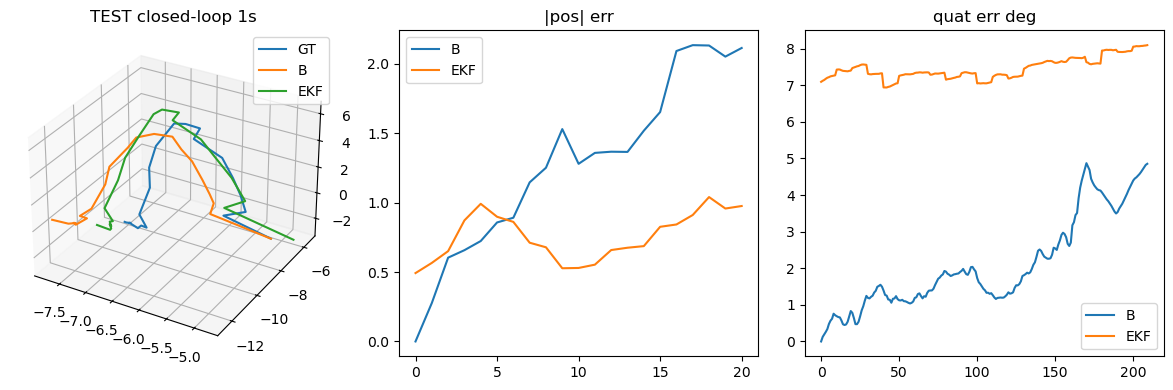

{
  "run_id": "B1_SS",
  "p_gt_final": 0.0,
  "k_unroll": 40,
  "ss_anneal": 0.4,
  "prev": "vel+quat",
  "n_train": 961,
  "n_val": 210,
  "n_test": 210,
  "B_closed": {
    "ate_m": 1.4225035905838013,
    "rte_m": 0.3014398217201233,
    "quat_mean_deg": 2.091238021850586
  },
  "B_teacher": {
    "ate_m": 1.2568671703338623,
    "rte_m": 0.2637159526348114,
    "quat_mean_deg": 0.11529940366744995
  },
  "GPS_vel": {
    "ate_m": 1.1033438444137573,
    "rte_m": 0.4506833553314209
  },
  "EKF": {
    "ate_m": 0.7753929495811462,
    "rte_m": 0.2014169692993164,
    "quat_mean_deg": 7.457713603973389
  }
}


In [11]:
diag = np.loadtxt(os.path.join(DATA, "filterstate.csv"), delimiter=",")
ekf_pos = diag[:, 1:4].astype(np.float32)
ekf_q = q_normalize(diag[:, 4:8].astype(np.float32))
ends_te = ends[te]
pos_ekf = ekf_pos[ends_te[::HOP_N]]
q_ekf = ekf_q[ends_te]
ate_e, rte_e = ate_rte(pos_ekf, pos_te_1s)
quat_e = float(q_ang_deg(q_ekf, q_te).mean())
print(f"EKF ATE {ate_e:.3f} m  RTE {rte_e:.3f} m  quat {quat_e:.2f} deg")

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(131, projection="3d")
ax.plot(*pos_te_1s.T, label="GT")
ax.plot(*pos_hat.T, label="B")
ax.plot(*pos_ekf.T, label="EKF")
ax.legend()
ax.set_title("TEST closed-loop 1s")
ax2 = fig.add_subplot(132)
ax2.plot(np.linalg.norm(pos_hat - pos_te_1s, axis=1), label="B")
ax2.plot(np.linalg.norm(pos_ekf - pos_te_1s, axis=1), label="EKF")
ax2.legend()
ax2.set_title("|pos| err")
ax3 = fig.add_subplot(133)
ax3.plot(q_ang_deg(q_hat, q_te), label="B")
ax3.plot(q_ang_deg(q_ekf, q_te), label="EKF")
ax3.legend()
ax3.set_title("quat err deg")
plt.tight_layout()
plt.show()

results = {
    "run_id": "B1_SS",
    "p_gt_final": p_gt_of(EPOCHS - 1),
    "k_unroll": K_UNROLL,
    "ss_anneal": SS_ANNEAL,
    "prev": "vel+quat",
    "n_train": int(len(X_tr)),
    "n_val": int(len(X_va)),
    "n_test": int(len(X_te)),
    "B_closed": {"ate_m": float(ate_a), "rte_m": float(rte_a), "quat_mean_deg": quat_a},
    "B_teacher": {"ate_m": float(ate_tf), "rte_m": float(rte_tf), "quat_mean_deg": quat_tf},
    "GPS_vel": {"ate_m": float(ate_g), "rte_m": float(rte_g)},
    "EKF": {"ate_m": float(ate_e), "rte_m": float(rte_e), "quat_mean_deg": quat_e},
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)
np.savez("results.npz", pos_te=pos_te_1s, pos_hat=pos_hat, pos_ekf=pos_ekf, q_te=q_te, q_hat=q_hat)
fig.savefig("results.png", dpi=120)
torch.save(
    {
        "run_id": "B1_SS",
        "state": model.state_dict(),
        "feat_mean": feat_mean, "feat_std": feat_std,
        "y_mean": y_mean, "y_std": y_std,
        "vel_m": vel_m, "vel_s": vel_s,
        "W": W, "stride": STRIDE, "K": K_UNROLL,
    },
    "option_b.pth",
)
print(json.dumps(results, indent=2))
